In [7]:
#!/usr/bin/env python3
"""coe_view.py - decode games.coe and draw the objects held in selected lines.

The Asteroids game ROM (games.coe) is 2048 words of 32 bits. This tool reads
it, works out which game and which record every line belongs to, decodes the
lines you select, and draws every object those lines touch on a 640 x 480
picture of the screen, the way the game starts.

    python3 coe_view.py games.coe                      # whole of game 0
    python3 coe_view.py games.coe --lines 35-61        # .coe file lines (as in an editor)
    python3 coe_view.py games.coe --addr 0x036-0x03E   # ROM addresses instead
    python3 coe_view.py games.coe --game 1             # whole of game 1
    python3 coe_view.py games.coe --game 0 --objects 0,1,8-10
    python3 coe_view.py games.coe --lines 35-61 --out rocks.png   # save, no window
    python3 coe_view.py games.coe --map                # print the partition table only
    python3 coe_view.py games.coe --interactive        # pick lines in a list, picture follows

Line numbers are the line numbers of the .coe file as a text editor shows
them (line 1 = first line). In the shipped file ROM address A is on line
A + 5, because four header lines come first; the tool does not assume that,
it counts the lines itself. A .mem file (one hex word per line) also works.

Needs Python 3.6+ and matplotlib (pip install matplotlib). --interactive also
needs tkinter, which most Python installers include.
"""
import argparse
import re
import sys

# ---------------------------------------------------------------------------
# The format (format version 2). (name, word, lsb, width, signed)
# ---------------------------------------------------------------------------
DIR_F = [("hdr_addr", 0, 0, 11, False), ("version", 0, 16, 8, False), ("valid", 0, 31, 1, False)]
HDR_F = [
    ("n_rule", 0, 0, 8, False), ("n_inp", 0, 8, 8, False), ("n_obj", 0, 16, 8, False),
    ("magic", 0, 24, 8, False),
    ("obj_base", 1, 0, 11, False), ("inp_base", 1, 16, 11, False),
    ("rule_base", 2, 0, 11, False), ("pal_base", 2, 16, 11, False),
    ("xmin", 3, 0, 11, True), ("xmax", 3, 16, 11, True),
    ("ymin", 4, 0, 11, True), ("ymax", 4, 16, 11, True),
    ("win_score", 5, 0, 7, False), ("init_score", 5, 8, 7, False),
    ("lose_at_zero", 5, 16, 1, False), ("spin_step", 5, 20, 3, False), ("spin_max", 5, 24, 5, False),
    ("hud_p1_x", 6, 0, 10, False), ("hud_p2_x", 6, 10, 10, False), ("hud_y", 6, 20, 9, False),
    ("hud_en", 6, 31, 1, False),
    ("collider_mask", 7, 0, 16, False), ("controlled_mask", 7, 16, 16, False),
    ("init_lives", 8, 0, 4, False), ("mark_color", 8, 8, 4, False), ("wave_watch", 8, 16, 16, False),
    ("wave_reload", 9, 0, 16, False),
]
OBJ_F = [
    ("x", 0, 0, 11, True), ("y", 0, 11, 11, True), ("w", 0, 22, 10, False),
    ("h", 1, 0, 10, False), ("vx", 1, 10, 6, True), ("vy", 1, 16, 6, True),
    ("color", 1, 22, 4, False), ("class", 1, 26, 4, False), ("owner", 1, 30, 2, False),
    ("enabled", 2, 0, 1, False), ("bmode", 2, 1, 2, False), ("tmode", 2, 3, 2, False),
    ("dir", 2, 5, 3, False), ("hp", 2, 8, 4, False), ("timer", 2, 12, 8, False),
    ("mark", 2, 20, 1, False), ("cool", 2, 21, 5, False),
]
INP_F = [("param", 0, 0, 16, False), ("class", 0, 16, 4, False), ("owner", 0, 20, 2, False),
         ("trigger", 0, 22, 2, False), ("button", 0, 24, 4, False), ("op", 0, 28, 4, False)]
MOVE_F = [("dir", 0, 0, 2, False), ("set_facing", 0, 2, 1, False), ("speed", 0, 4, 6, False)]
SPAWN_F = [("pool", 0, 0, 4, False), ("cooldown", 0, 8, 8, False)]
RULE_F = [
    ("last", 0, 0, 1, False), ("owner_rel", 0, 16, 2, False), ("other", 0, 20, 4, False),
    ("self", 0, 24, 4, False), ("event", 0, 28, 4, False),
    ("motion", 1, 0, 2, False), ("spin", 1, 2, 1, False), ("copy_owner", 1, 3, 1, False),
    ("copy_color", 1, 4, 1, False), ("counter", 1, 5, 1, False), ("score_sel", 1, 8, 3, False),
    ("score_delta", 1, 12, 4, True), ("self_fate", 1, 16, 3, False), ("other_fate", 1, 19, 3, False),
    ("flip_x", 1, 22, 1, False), ("flip_y", 1, 23, 1, False), ("split_class", 1, 24, 4, False),
]

OWNER = ["none", "P1", "P2", "?"]
BMODE = ["CLAMP", "BOUNCE", "WRAP", "DESTROY"]
TMODE = ["COUNTDOWN", "FREEZE", "LIFETIME", "SHIELD"]
HEADING = ["E", "NE", "N", "NW", "W", "SW", "S", "SE"]
HX = [1, 1, 0, -1, -1, -1, 0, 1]
HY = [0, -1, -1, -1, 0, 1, 1, 1]
MOVE_DIR = ["RIGHT", "LEFT", "DOWN", "UP"]
BUTTON = ["P1_UP (W)", "P1_DOWN (S)", "P1_LEFT (A)", "P1_RIGHT (D)", "P1_FIRE (F)",
          "P2_UP (Up)", "P2_DOWN (Down)", "P2_LEFT (Left)", "P2_RIGHT (Right)", "P2_FIRE (Enter)"]
TRIGGER = ["HELD", "PRESSED", "?", "?"]
OP = {1: "MOVE", 2: "SPAWN"}
EVENT = {0: "COLLIDE", 1: "EDGE"}
OWNER_REL = ["ANY", "SAME owner", "DIFFERENT owner", "?"]
MOTION = ["NONE", "BOUNCE", "STOP", "?"]
FATE = ["NONE", "DAMAGE", "DESTROY", "RESPAWN", "SPLIT", "NONE", "NONE", "NONE"]
SCORE_SEL = ["nobody", "self's owner", "other's owner", "self's opponent", "other's opponent",
             "P1", "P2", "nobody"]

# Class numbers are all the ROM stores. These are the names used in the
# shipped games.coe (slot -> list); --names overrides them.
CLASS_NAMES = {
    0: ["SHIP", "SHOT", "ROCK_L", "ROCK_M", "ROCK_S"],
    1: ["SHIP", "SHOT", "ROCK_M", "ROCK_S"],
    2: ["SHIP", "SHOT", "ROCK_L", "ROCK_M", "ROCK_S"],
    3: ["SHIP", "SHOT", "ROCK_L", "ROCK_M", "ROCK_S"],
}
GAME_NAMES = {0: "Asteroids Versus", 1: "Asteroids Swarm", 2: "Asteroids Duel",
              3: "Asteroids Sudden Death"}


def unpack(fields, words):
    out = {}
    for name, w, lsb, width, signed in fields:
        v = (words[w] >> lsb) & ((1 << width) - 1)
        if signed and v >> (width - 1):
            v -= 1 << width
        out[name] = v
    return out


# ---------------------------------------------------------------------------
# Reading the file
# ---------------------------------------------------------------------------
def read_rom(path):
    """Return (words, line_of_addr): the ROM words and the 1-based file line
    each word sits on."""
    words, lines = [], []
    text = open(path).read().splitlines()
    is_coe = path.lower().endswith(".coe") or any("memory_initialization_vector" in t.lower() for t in text)
    in_vec = not is_coe
    for n, raw in enumerate(text, 1):
        t = raw.split(";")[0] if is_coe else raw.split("//")[0]
        if is_coe and not in_vec:
            m = re.search(r"memory_initialization_vector\s*=", t, re.I)
            if not m:
                continue
            in_vec = True
            t = t[m.end():]
        for tok in re.split(r"[,\s]+", t):
            if tok and re.fullmatch(r"[0-9A-Fa-f]+", tok):
                words.append(int(tok, 16) & 0xFFFFFFFF)
                lines.append(n)
    if len(words) < 4:
        sys.exit("%s: found only %d words - is this a games.coe / games.mem file?" % (path, len(words)))
    return words, lines


class Rom(object):
    """The ROM image with every address labelled."""

    def __init__(self, path, names=None):
        self.words, self.line_of = read_rom(path)
        self.addr_of_line = {}
        for a, ln in enumerate(self.line_of):
            self.addr_of_line.setdefault(ln, []).append(a)
        self.label = {}          # addr -> (game, section, index, word_in_record)
        self.games = {}
        self.names = names or CLASS_NAMES
        for g in range(4):
            self.label[g] = (None, "directory", g, 0)
        for g in range(4):
            d = unpack(DIR_F, [self.words[g]])
            if not d["valid"]:
                continue
            h0 = d["hdr_addr"]
            hdr = unpack(HDR_F, self.words[h0:h0 + 10])
            if hdr["magic"] != 0xA5:
                continue
            pal = [self.words[hdr["pal_base"] + i] & 0xFFF for i in range(16)]
            self.games[g] = {"dir": d, "hdr_addr": h0, "hdr": hdr, "pal": pal}
            for k in range(10):
                self.label[h0 + k] = (g, "header", 0, k)
            for i in range(16):
                self.label[hdr["pal_base"] + i] = (g, "palette", i, 0)
            for i in range(hdr["n_obj"]):
                for k in range(3):
                    self.label[hdr["obj_base"] + 3 * i + k] = (g, "object", i, k)
            for i in range(hdr["n_inp"]):
                self.label[hdr["inp_base"] + i] = (g, "input", i, 0)
            for i in range(hdr["n_rule"]):
                for k in range(2):
                    self.label[hdr["rule_base"] + 2 * i + k] = (g, "rule", i, k)

    # ---- names
    def cls(self, g, c):
        names = self.names.get(g, [])
        return names[c] if c < len(names) else "class %d" % c

    def obj(self, g, i):
        b = self.games[g]["hdr"]["obj_base"] + 3 * i
        return unpack(OBJ_F, self.words[b:b + 3])

    # ---- one-line meaning of an address
    def meaning(self, a):
        w = self.words[a]
        lab = self.label.get(a)
        if lab is None:
            return "unused (reads as 0)" if w == 0 else "not referenced by any header"
        g, sec, i, k = lab
        if sec == "directory":
            d = unpack(DIR_F, [w])
            if not d["valid"]:
                return "DIR[%d] empty slot" % i
            return "DIR[%d] game %d -> header at 0x%03X, format v%d" % (i, i, d["hdr_addr"], d["version"])
        G = self.games[g]
        if sec == "header":
            fs = [(n, v) for n, v in unpack(HDR_F, self.words[G["hdr_addr"]:G["hdr_addr"] + 10]).items()
                  if [f for f in HDR_F if f[0] == n][0][1] == k]
            return "game %d HEADER H%d  %s" % (g, k, " ".join("%s=%s" % (n, v) for n, v in fs))
        if sec == "palette":
            return "game %d PALETTE[%d] = #%03X" % (g, i, w & 0xFFF)
        if sec == "object":
            o = self.obj(g, i)
            part = ["x, y, w", "h, velocity, colour, class, owner", "enabled, modes, heading, timers"][k]
            return "game %d OBJECT %d word %d (%s): %s" % (g, i, k, part, describe_obj(self, g, i, o))
        if sec == "input":
            return "game %d INPUT %d: %s" % (g, i, describe_inp(self, g, unpack(INP_F, [w])))
        if sec == "rule":
            b = G["hdr"]["rule_base"] + 2 * i
            return "game %d RULE %d word %d: %s" % (g, i, k, describe_rule(self, g, unpack(RULE_F, self.words[b:b + 2])))
        return ""


def describe_obj(rom, g, i, o):
    s = "%s %s at (%d,%d) %dx%d v=(%d,%d) colour %d" % (
        rom.cls(g, o["class"]), OWNER[o["owner"]], o["x"], o["y"], o["w"], o["h"], o["vx"], o["vy"], o["color"])
    s += " %s %s" % ("enabled" if o["enabled"] else "starts disabled (pool)", BMODE[o["bmode"]])
    if o["timer"]:
        s += " %s %d frames" % (TMODE[o["tmode"]], o["timer"])
    if o["mark"]:
        s += " marker facing %s" % HEADING[o["dir"]]
    return s


def describe_inp(rom, g, m):
    who = "%s owned by %s" % (rom.cls(g, m["class"]), "anyone" if m["owner"] == 0 else OWNER[m["owner"]])
    key = BUTTON[m["button"]] if m["button"] < 10 else "button %d" % m["button"]
    if m["op"] == 1:
        p = unpack(MOVE_F, [m["param"]])
        act = "MOVE %s at %d px/frame%s" % (MOVE_DIR[p["dir"]], p["speed"], ", turn to face it" if p["set_facing"] else "")
    elif m["op"] == 2:
        p = unpack(SPAWN_F, [m["param"]])
        act = "FIRE: activate a free %s from the pool, then wait %d frames" % (rom.cls(g, p["pool"]), p["cooldown"])
    else:
        act = "no operation"
    return "%s %s -> %s: %s" % (key, TRIGGER[m["trigger"]], who, act)


def describe_rule(rom, g, r):
    if r["event"] == 0:
        when = "%s touches %s (%s)" % (rom.cls(g, r["self"]), rom.cls(g, r["other"]), OWNER_REL[r["owner_rel"]])
    else:
        edges = [n for b, n in ((1, "left"), (2, "right"), (4, "top"), (8, "bottom")) if r["other"] & b]
        when = "%s reaches the %s edge" % (rom.cls(g, r["self"]), "/".join(edges) or "no")
    then = []
    if r["motion"]:
        then.append("self " + MOTION[r["motion"]])
    if r["score_sel"] and r["score_delta"]:
        then.append("%s %s %+d" % (SCORE_SEL[r["score_sel"]], "lives" if r["counter"] else "score", r["score_delta"]))
    if r["self_fate"]:
        then.append("self " + FATE[r["self_fate"]])
    if r["other_fate"]:
        f = FATE[r["other_fate"]]
        then.append("other " + (f + " into two " + rom.cls(g, r["split_class"]) if f == "SPLIT" else f))
    if r["last"]:
        then.append("stop checking rules")
    return "WHEN %s THEN %s" % (when, ", ".join(then) or "nothing")


# ---------------------------------------------------------------------------
# Selection
# ---------------------------------------------------------------------------
def parse_ranges(s):
    out = []
    for part in s.split(","):
        part = part.strip()
        if not part:
            continue
        if "-" in part[1:]:
            a, b = part.split("-", 1) if not part.startswith("-") else (part, part)
            out.extend(range(int(a, 0), int(b, 0) + 1))
        else:
            out.append(int(part, 0))
    return out


def selected_addrs(rom, args):
    if args.lines:
        addrs = []
        for ln in parse_ranges(args.lines):
            addrs.extend(rom.addr_of_line.get(ln, []))
        return sorted(set(addrs))
    if args.addr:
        return sorted(a for a in set(parse_ranges(args.addr)) if 0 <= a < len(rom.words))
    g = args.game if args.game is not None else 0
    if g not in rom.games:
        sys.exit("game %d is not in this ROM" % g)
    h = rom.games[g]["hdr"]
    if args.objects:
        return sorted(h["obj_base"] + 3 * i + k for i in parse_ranges(args.objects) for k in range(3)
                      if i < h["n_obj"])
    return sorted(a for a, lab in rom.label.items() if lab[0] == g)


# ---------------------------------------------------------------------------
# Printing
# ---------------------------------------------------------------------------
def print_map(rom):
    print("ROM: %d words. Address A sits on file line %s." % (
        len(rom.words), "A + %d" % (rom.line_of[0] - 0) if all(
            rom.line_of[a] == rom.line_of[0] + a for a in range(len(rom.words))) else "(see column)"))
    print("%-13s %-13s %-6s %s" % ("addresses", "file lines", "words", "contents"))
    print("%-13s %-13s %-6d %s" % ("0x000-0x003", "%d-%d" % (rom.line_of[0], rom.line_of[3]), 4,
                                   "directory: word g -> header of game g"))
    last = 3
    for g in sorted(rom.games):
        G = rom.games[g]
        h = G["hdr"]
        secs = [(G["hdr_addr"], 10, "header"), (h["pal_base"], 16, "palette (16 colours)"),
                (h["obj_base"], 3 * h["n_obj"], "objects (%d x 3 words)" % h["n_obj"]),
                (h["inp_base"], h["n_inp"], "key mappings (%d x 1 word)" % h["n_inp"]),
                (h["rule_base"], 2 * h["n_rule"], "rules (%d x 2 words)" % h["n_rule"])]
        for a, n, what in secs:
            if n:
                print("0x%03X-0x%03X   %-13s %-6d game %d %s: %s" % (
                    a, a + n - 1, "%d-%d" % (rom.line_of[a], rom.line_of[a + n - 1]), n, g,
                    GAME_NAMES.get(g, ""), what))
                last = max(last, a + n - 1)
    if last + 1 < len(rom.words):
        print("0x%03X-0x%03X   %-13s %-6d unused, all 0" % (
            last + 1, len(rom.words) - 1, "%d-%d" % (rom.line_of[last + 1], rom.line_of[-1]),
            len(rom.words) - last - 1))


def print_selection(rom, addrs):
    print("%-5s %-5s %-9s %s" % ("line", "addr", "word", "meaning"))
    for a in addrs:
        print("%-5d %03X   %08X  %s" % (rom.line_of[a], a, rom.words[a], rom.meaning(a)))


# ---------------------------------------------------------------------------
# Drawing
# ---------------------------------------------------------------------------
def rgb(c12):
    return "#%02X%02X%02X" % (((c12 >> 8) & 15) * 17, ((c12 >> 4) & 15) * 17, (c12 & 15) * 17)


def draw(rom, addrs, ax, title=None):
    from matplotlib.patches import Rectangle
    ax.clear()
    picked = {}
    games = set()
    for a in addrs:
        lab = rom.label.get(a)
        if lab and lab[0] is not None:
            games.add(lab[0])
            if lab[1] == "object":
                picked.setdefault(lab[0], set()).add(lab[2])
    g = min(picked) if picked else (min(games) if games else min(rom.games))
    G = rom.games[g]
    h, pal = G["hdr"], G["pal"]
    objs = sorted(picked.get(g, []))
    live = [i for i in objs if rom.obj(g, i)["enabled"]]
    pool = [i for i in objs if not rom.obj(g, i)["enabled"]]

    shelf_h = 0
    if pool:
        shelf_h = 40 + 44 * ((len(pool) + 11) // 12)
    ax.set_facecolor("white")
    ax.add_patch(Rectangle((0, 0), 640, 480, facecolor=rgb(pal[0]), edgecolor="#888", lw=1))
    ax.add_patch(Rectangle((h["xmin"], h["ymin"]), h["xmax"] - h["xmin"], h["ymax"] - h["ymin"],
                           fill=False, edgecolor="#6a6", lw=1, ls="--"))
    ax.text(h["xmin"] + 4, h["ymax"] - 6, "arena %d..%d x %d..%d" % (h["xmin"], h["xmax"], h["ymin"], h["ymax"]),
            color="#6a6", fontsize=7)
    if h["hud_en"]:
        for x, who in ((h["hud_p1_x"], "P1 score"), (h["hud_p2_x"], "P2 score")):
            ax.add_patch(Rectangle((x, h["hud_y"]), 90, 18, fill=False, edgecolor="#777", lw=0.8, ls=":"))
            ax.text(x + 2, h["hud_y"] + 13, who, color="#999", fontsize=6)

    def one(i, x, y, faded):
        o = rom.obj(g, i)
        col = rgb(pal[o["color"]]) if o["color"] else "#555"
        ax.add_patch(Rectangle((x, y), o["w"], o["h"], facecolor=col, edgecolor="white" if not faded else col,
                               lw=0.6, alpha=0.45 if faded else 1.0, ls="--" if faded else "-"))
        if o["mark"]:
            d = o["dir"]
            mx = x + o["w"] - 4 if HX[d] > 0 else x if HX[d] < 0 else x + (o["w"] - 4) // 2
            my = y if HY[d] < 0 else y + o["h"] - 4 if HY[d] > 0 else y + (o["h"] - 4) // 2
            ax.add_patch(Rectangle((mx, my), 4, 4, facecolor=rgb(pal[h["mark_color"]]), lw=0))
        if not faded and (o["vx"] or o["vy"]):
            ax.annotate("", xy=(x + o["w"] / 2 + 8 * o["vx"], y + o["h"] / 2 + 8 * o["vy"]),
                        xytext=(x + o["w"] / 2, y + o["h"] / 2),
                        arrowprops=dict(arrowstyle="->", color="#ff5", lw=1))
        if faded:
            ax.text(x, y + o["h"] + 9, "%d %s" % (i, rom.cls(g, o["class"])), color="#333", fontsize=5.5)
        else:
            ax.text(x, y - 3, "%d %s" % (i, rom.cls(g, o["class"])), color="white", fontsize=6.5)

    for i in live:
        o = rom.obj(g, i)
        one(i, o["x"], o["y"], False)
    if pool:
        y0 = 480 + 30
        ax.text(0, y0 - 8, "starts disabled - pool slots, placed when spawned / split (drawn at template size)",
                color="#333", fontsize=7)
        for n, i in enumerate(pool):
            one(i, 8 + 53 * (n % 12), y0 + 10 + 44 * (n // 12), True)

    ax.set_xlim(-10, 650)
    ax.set_ylim(480 + shelf_h + 10, -20)
    ax.set_aspect("equal")
    ax.tick_params(labelsize=7)
    ax.set_title(title or "game %d %s: %d object(s) from the selected lines (velocity arrows x8)"
                 % (g, GAME_NAMES.get(g, ""), len(objs)), fontsize=9)
    others = sorted(set(picked) - {g})
    if others:
        ax.text(0, -8, "objects of game(s) %s also selected - shown one game at a time" % others,
                color="#c33", fontsize=7)
    return g, objs


# ---------------------------------------------------------------------------
# Interactive picker
# ---------------------------------------------------------------------------
def interactive(rom):
    try:
        import tkinter as tk
        from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
        from matplotlib.figure import Figure
    except ImportError as e:
        sys.exit("--interactive needs tkinter and matplotlib (%s)" % e)
    root = tk.Tk()
    root.title("games.coe viewer - select lines (Ctrl/Shift for several)")
    left = tk.Frame(root)
    left.pack(side=tk.LEFT, fill=tk.Y)
    lb = tk.Listbox(left, selectmode=tk.EXTENDED, width=78, font=("Courier", 9))
    sb = tk.Scrollbar(left, command=lb.yview)
    lb.config(yscrollcommand=sb.set)
    sb.pack(side=tk.RIGHT, fill=tk.Y)
    lb.pack(side=tk.LEFT, fill=tk.Y, expand=True)
    used = max(a for a in rom.label) + 1
    rows = list(range(min(len(rom.words), used + 1)))
    for a in rows:
        lb.insert(tk.END, "%4d  %03X  %08X  %s" % (rom.line_of[a], a, rom.words[a], rom.meaning(a)[:60]))
    right = tk.Frame(root)
    right.pack(side=tk.RIGHT, fill=tk.BOTH, expand=True)
    fig = Figure(figsize=(8, 7), dpi=100)
    ax = fig.add_subplot(111)
    canvas = FigureCanvasTkAgg(fig, master=right)
    canvas.get_tk_widget().pack(fill=tk.BOTH, expand=True)
    info = tk.Text(right, height=8, font=("Courier", 9))
    info.pack(fill=tk.X)

    def update(_evt=None):
        addrs = [rows[i] for i in lb.curselection()]
        draw(rom, addrs, ax)
        canvas.draw()
        info.delete("1.0", tk.END)
        for a in addrs[:200]:
            info.insert(tk.END, "line %d  0x%03X  %08X  %s\n" % (rom.line_of[a], a, rom.words[a], rom.meaning(a)))
    lb.bind("<<ListboxSelect>>", update)
    update()
    root.mainloop()


def main(argv=None):
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("file", help="games.coe (or games.mem)")
    ap.add_argument("--lines", help="file line numbers, e.g. 35-61,90")
    ap.add_argument("--addr", help="ROM addresses, e.g. 0x01E-0x074")
    ap.add_argument("--game", type=int, help="game slot 0..3 (default 0)")
    ap.add_argument("--objects", help="object indices within --game, e.g. 0,1,8-10")
    ap.add_argument("--names", help="class names per game, e.g. '0:SHIP,SHOT,ROCK_L;1:SHIP,SHOT'")
    ap.add_argument("--out", help="save the picture to this file instead of opening a window")
    ap.add_argument("--map", action="store_true", help="print the partition table and stop")
    ap.add_argument("--interactive", action="store_true", help="pick lines from a list")
    a = ap.parse_args(argv)

    names = None
    if a.names:
        names = {}
        for part in a.names.split(";"):
            g, lst = part.split(":")
            names[int(g)] = lst.split(",")
    rom = Rom(a.file, names)
    if a.interactive:
        interactive(rom)
        return
    print_map(rom)
    if a.map:
        return
    addrs = selected_addrs(rom, a)
    print()
    print_selection(rom, addrs)
    import matplotlib
    if a.out:
        matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(8, 7))
    draw(rom, addrs, ax)
    fig.tight_layout()
    if a.out:
        fig.savefig(a.out, dpi=130)
        print("\nwrote %s" % a.out)
    else:
        plt.show()


if __name__ == "__main__":
    # Pass explicit arguments instead of reading sys.argv which contains notebook connection flags
    main(["/content/games.coe", "--out", "rocks.png"])

ROM: 2043 words. Address A sits on file line (see column).
addresses     file lines    words  contents
0x000-0x003   5-8           4      directory: word g -> header of game g
0x004-0x00D   9-18          10     game 0 Asteroids Versus: header
0x00E-0x01D   19-34         16     game 0 Asteroids Versus: palette (16 colours)
0x01E-0x074   35-121        87     game 0 Asteroids Versus: objects (29 x 3 words)
0x075-0x07E   122-131       10     game 0 Asteroids Versus: key mappings (10 x 1 word)
0x07F-0x08E   132-147       16     game 0 Asteroids Versus: rules (8 x 2 words)
0x08F-0x7FA   149-2048      1900   unused, all 0

line  addr  word      meaning
9     004   A51D0A08  game 0 HEADER H0  n_rule=8 n_inp=10 n_obj=29 magic=165
10    005   0075001E  game 0 HEADER H1  obj_base=30 inp_base=117
11    006   000E007F  game 0 HEADER H2  rule_base=127 pal_base=14
12    007   02800000  game 0 HEADER H3  xmin=0 xmax=640
13    008   01E00000  game 0 HEADER H4  ymin=0 ymax=480
14    009   0001003C  game

ROM: 2043 words. Address A sits on file line (see column).
addresses     file lines    words  contents
0x000-0x003   5-8           4      directory: word g -> header of game g
0x004-0x00D   9-18          10     game 0 Asteroids Versus: header
0x00E-0x01D   19-34         16     game 0 Asteroids Versus: palette (16 colours)
0x01E-0x074   35-121        87     game 0 Asteroids Versus: objects (29 x 3 words)
0x075-0x07E   122-131       10     game 0 Asteroids Versus: key mappings (10 x 1 word)
0x07F-0x08E   132-147       16     game 0 Asteroids Versus: rules (8 x 2 words)
0x08F-0x7FA   149-2048      1900   unused, all 0

line  addr  word      meaning
41    024   01000000  game 0 OBJECT 2 word 0 (x, y, w): SHOT P1 at (0,0) 4x4 v=(6,0) colour 7 starts disabled (pool) WRAP LIFETIME 45 frames
42    025   45C01804  game 0 OBJECT 2 word 1 (h, velocity, colour, class, owner): SHOT P1 at (0,0) 4x4 v=(6,0) colour 7 starts disabled (pool) WRAP LIFETIME 45 frames
43    026   0002D014  game 0 OBJECT 2 

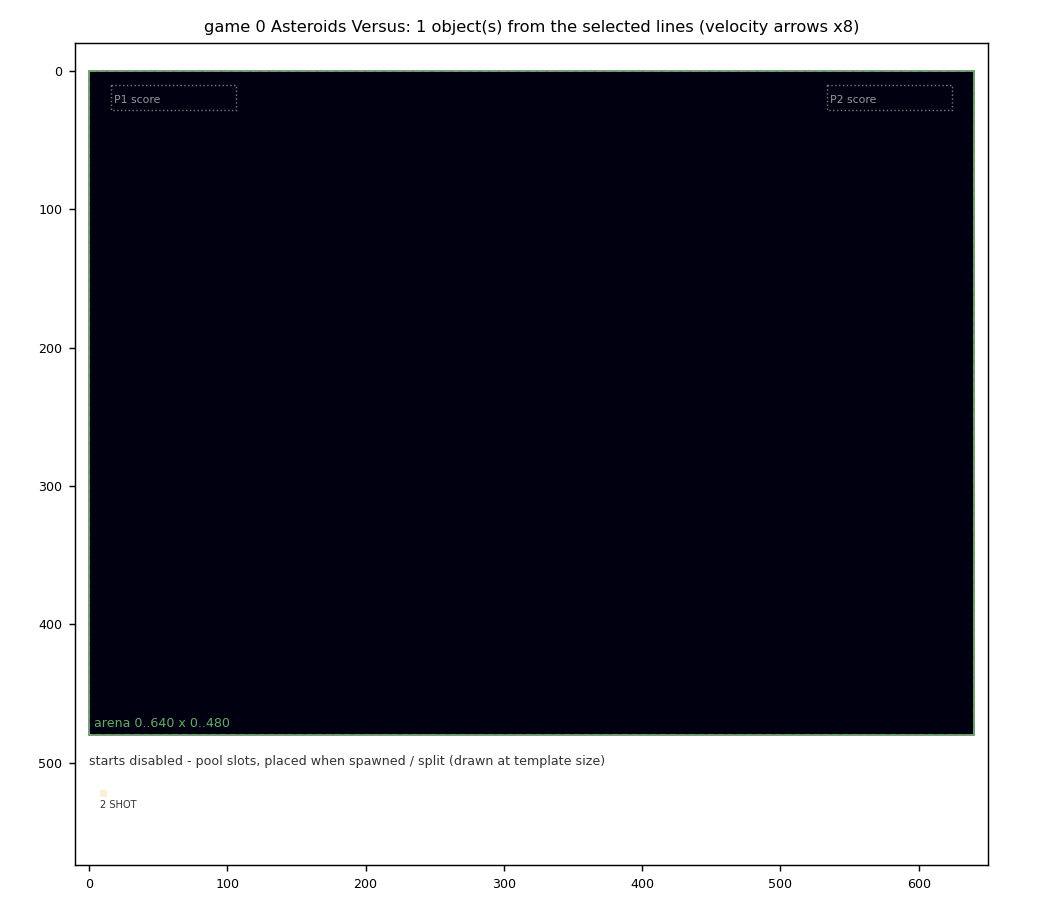

In [16]:
from IPython.display import Image, display

# Choose the file line numbers you want to render (e.g., '35-61', '120-140', or multiple separated by commas)
lines_to_render = "41-43"
output_image = "selected_rocks.png"

# Run the main parser with the specified line selections
main(["/content/games.coe", "--lines", lines_to_render, "--out", output_image])

# Display the generated visualization inside the notebook
display(Image(output_image))